# Langkah 1 — Persiapan Lingkungan & Dataset Deteksi Plat (YOLOv8n)
**Proyek:** Smart Gate FT UNTIRTA — ALPR plat nomor Indonesia (YOLOv8n + PaddleOCR)

Hasil akhir langkah ini:
1. Lingkungan Colab dengan GPU dan Ultralytics YOLOv8 siap pakai.
2. Struktur folder proyek di Google Drive (aman walau sesi Colab terputus).
3. Dataset deteksi plat format YOLO sudah terunduh, dicek, dan punya file `plate.yaml`.

> PaddleOCR **sengaja belum dipasang** di notebook ini. PaddlePaddle dan PyTorch memakai library CUDA yang bisa bentrok dalam satu sesi Colab, jadi OCR dikerjakan di notebook terpisah (langkah 3–4).

**Sebelum mulai:** Runtime → Change runtime type → **T4 GPU**.

## 1. Cek GPU

In [1]:
!nvidia-smi

Wed Nov 11 05:40:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Hubungkan Google Drive dan buat struktur folder
Semua data, bobot model, dan hasil evaluasi disimpan di `MyDrive/alpr/`.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = '/content/drive/MyDrive/0-KEPSTON/model_alpr'
FOLDERS = [
    'data/raw/publik',      # dataset unduhan (Roboflow)
    'data/raw/lokal',       # foto sendiri dari webcam gerbang FT UNTIRTA
    'data/detect',          # dataset deteksi final (format YOLO)
    'data/ocr',             # potongan plat + label teks (untuk PaddleOCR, langkah 3)
    'models',               # bobot hasil training (best.pt, OpenVINO, dll.)
    'eval',                 # hasil evaluasi & contoh gagal
]
for f in FOLDERS:
    os.makedirs(os.path.join(ROOT, f), exist_ok=True)
print('Struktur folder siap di', ROOT)
!ls -R {ROOT} | head -40

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Struktur folder siap di /content/drive/MyDrive/0-KEPSTON/model_alpr
/content/drive/MyDrive/0-KEPSTON/model_alpr:
data
eval
models

/content/drive/MyDrive/0-KEPSTON/model_alpr/data:
detect
ocr
raw

/content/drive/MyDrive/0-KEPSTON/model_alpr/data/detect:

/content/drive/MyDrive/0-KEPSTON/model_alpr/data/ocr:

/content/drive/MyDrive/0-KEPSTON/model_alpr/data/raw:
lokal
publik

/content/drive/MyDrive/0-KEPSTON/model_alpr/data/raw/lokal:

/content/drive/MyDrive/0-KEPSTON/model_alpr/data/raw/publik:

/content/drive/MyDrive/0-KEPSTON/model_alpr/eval:

/content/drive/MyDrive/0-KEPSTON/model_alpr/models:


## 3. Pasang Ultralytics (YOLOv8) dan Roboflow

In [4]:
!pip install -q -U ultralytics roboflow
import ultralytics
ultralytics.checks()   # menampilkan versi, GPU, RAM, dan disk

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/235.7 GB disk)


## 4. Uji cepat YOLOv8n
Memastikan instalasi berjalan: model `yolov8n.pt` (pretrained COCO) diunduh lalu dipakai mendeteksi gambar contoh.
Kalau keluar daftar objek (bus, person, …), lingkungan sudah siap.

{'stop sign', 'person', 'bus'}


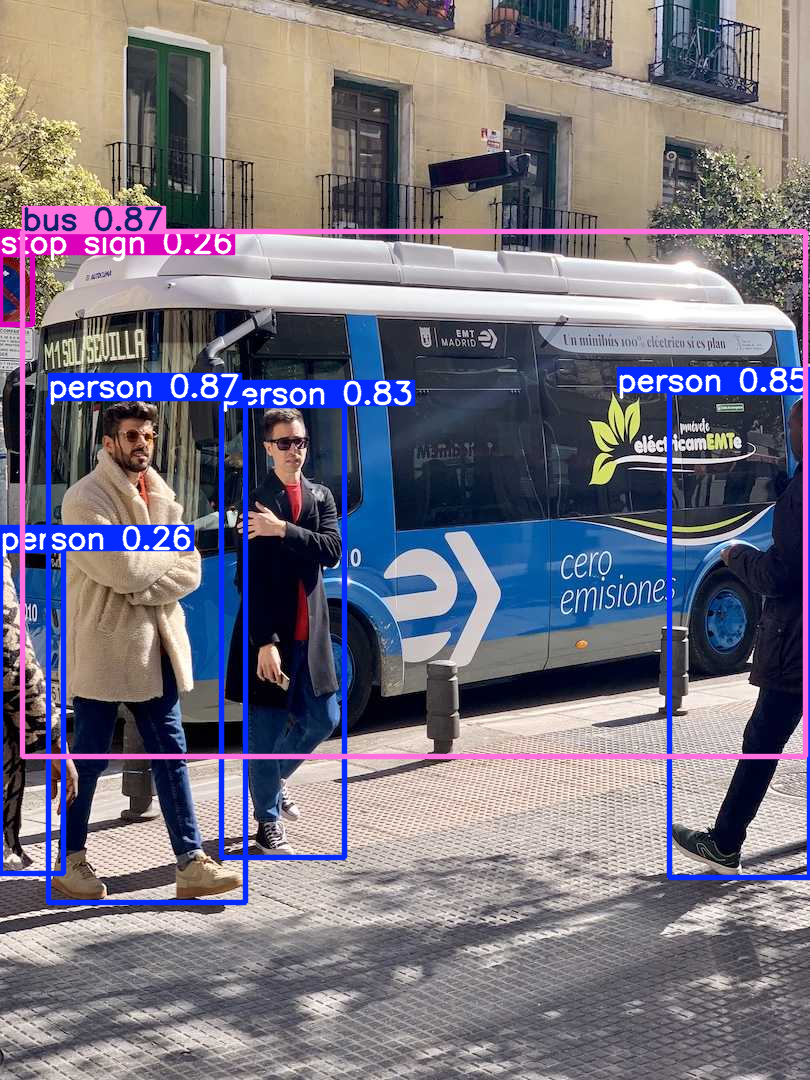

In [5]:
from ultralytics import YOLO
model = YOLO('yolov8n.pt')
res = model.predict('https://ultralytics.com/images/bus.jpg', conf=0.25, verbose=False)
print({model.names[int(c)] for c in res[0].boxes.cls})
res[0].show()

## 5. Unduh dataset plat Indonesia dari Roboflow Universe
1. Buat akun gratis di [roboflow.com](https://roboflow.com), lalu salin **Private API Key** dari *Settings → API Keys*.
2. Buka halaman dataset, misalnya [Indonesian License Plates](https://universe.roboflow.com/samuel-nathaniel-h-f0y9g/indonesian-license-plates), pilih versi terbaru, lalu klik **Download Dataset → YOLOv8** untuk melihat nama workspace, project, dan nomor versinya.
3. Isi variabel di bawah. Jangan membagikan API key di laporan atau repo publik.

Untuk menggabungkan beberapa dataset, ulangi sel ini dengan workspace/project lain.

In [12]:
from roboflow import Roboflow
from getpass import getpass
import os

rf = Roboflow(api_key=getpass('Roboflow API key (yang baru): '))
DATASETS = [
    # (workspace, project, version)
    ('samuel-nathaniel-h-f0y9g', 'indonesian-license-plates', 1),   # sudah diunduh, akan dilewati
    ('habib-robbani', 'indonesian-motorcycle-plate', 1),
    ('muhammads-workspace-a5wiz', 'indonesia-anpr-hruo7', 1),
    ('raflis-ta', 'indonesian-license-plate-detection-zvnve', 1),
]
for ws, pj, ver in DATASETS:
    dst = f'{ROOT}/data/raw/publik/{pj}'
    if os.path.exists(dst) and os.listdir(dst):
        print('Lewati (sudah ada):', pj); continue
    try:
        rf.workspace(ws).project(pj).version(ver).download('yolov8', location=dst)
        print('OK:', pj)
    except Exception as e:
        print('GAGAL:', pj, '->', e)

Roboflow API key (yang baru): ··········
Lewati (sudah ada): indonesian-license-plates
loading Roboflow workspace...
loading Roboflow project...
GAGAL: indonesia-license-plate -> Version number 1 is not found.
loading Roboflow workspace...
loading Roboflow project...
GAGAL: indonesia-anpr -> Version number 1 is not found.
Lewati (sudah ada): indonesian-motorcycle-plate
Lewati (sudah ada): indonesia-anpr-hruo7
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to /content/drive/MyDrive/0-KEPSTON/model_alpr/data/raw/publik/indonesian-license-plate-detection-zvnve in yolov8:: 100%|██████████| 2143/2143 [00:25<00:00, 83.25it/s] 

OK: indonesian-license-plate-detection-zvnve


## 6. Gabungkan ke folder `data/detect` dengan satu kelas `plate`
Dataset dari Roboflow bisa memakai nama kelas atau nomor kelas berbeda. Sel ini menyalin semua gambar dan label ke `data/detect/{train,valid,test}` dan **memaksa semua kelas menjadi `0` (plate)**.
Nama file diberi awalan nama sumber supaya tidak bertabrakan.

In [16]:
import hashlib, random, shutil
from pathlib import Path

SRC_ROOT = Path(f'{ROOT}/data/raw/publik')
DST = Path(f'{ROOT}/data/detect')
RATIO = (0.7, 0.2, 0.1)          # train / valid / test
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# Kelas yang DIAMBIL sebagai plat untuk tiap dataset (nomor kelas sesuai data.yaml masing-masing).
# Dataset yang tidak disebut di sini: semua kelasnya dianggap plat.
KEEP_CLASSES = {
    'indonesian-motorcycle-plate': {1},   # 0 = motor (dibuang), 1 = plate (diambil)
}

def to_yolo_lines(lbl_path, src_name):
    keep = KEEP_CLASSES.get(src_name)
    out = []
    for ln in lbl_path.read_text().splitlines():
        p = ln.split()
        if not p:
            continue
        if keep is not None and int(float(p[0])) not in keep:
            continue                                      # buang kelas non-plat
        if len(p) == 5:                                   # kotak: kelas x y w h
            out.append(' '.join(['0'] + p[1:]))
        elif len(p) > 5 and len(p) % 2 == 1:              # polygon -> kotak
            xs, ys = list(map(float, p[1::2])), list(map(float, p[2::2]))
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            out.append(f'0 {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}')
    return out

# 1) Kumpulkan semua gambar + label dari semua dataset
groups, seen = {}, set()
stat = {'duplikat': 0, 'tanpa_label': 0, 'background': 0}
for img in SRC_ROOT.rglob('*'):
    if img.suffix.lower() not in IMG_EXT or img.parent.name != 'images':
        continue
    lbl = img.parent.parent / 'labels' / (img.stem + '.txt')
    if not lbl.exists():
        stat['tanpa_label'] += 1; continue
    h = hashlib.md5(img.read_bytes()).hexdigest()
    if h in seen:
        stat['duplikat'] += 1; continue
    seen.add(h)
    src_name = img.relative_to(SRC_ROOT).parts[0]
    lines = to_yolo_lines(lbl, src_name)
    if not lines:
        stat['background'] += 1
    key = src_name + '__' + img.stem.split('.rf.')[0]    # foto asli + augmentasinya = satu grup
    groups.setdefault(key, []).append((img, lines))

# 2) Bagi ulang 70/20/10 per grup (acak, seed tetap supaya hasilnya bisa diulang)
keys = sorted(groups); random.seed(42); random.shuffle(keys)
n = len(keys); n_tr = int(n * RATIO[0]); n_va = int(n * RATIO[1])
split_of = {k: ('train' if i < n_tr else 'valid' if i < n_tr + n_va else 'test') for i, k in enumerate(keys)}

# 3) Salin ke data/detect (folder lama dihapus dulu supaya bersih)
if DST.exists():
    shutil.rmtree(DST)
count = {'train': 0, 'valid': 0, 'test': 0}
for k, items in groups.items():
    sp = split_of[k]
    (DST / sp / 'images').mkdir(parents=True, exist_ok=True)
    (DST / sp / 'labels').mkdir(parents=True, exist_ok=True)
    for i, (img, lines) in enumerate(items):
        name = f'{k}_{i}'
        shutil.copy(img, DST / sp / 'images' / (name + img.suffix.lower()))
        (DST / sp / 'labels' / (name + '.txt')).write_text('\n'.join(lines))
        count[sp] += 1

print('Jumlah gambar per split:', count)
print('Statistik:', stat)

Jumlah gambar per split: {'train': 2205, 'valid': 622, 'test': 319}
Statistik: {'duplikat': 3, 'tanpa_label': 0, 'background': 9}


## 7. Cek kualitas dataset
Memastikan setiap gambar punya label, tidak ada label kosong, dan koordinat bounding box valid (0–1).

In [20]:
def cek_split(split):
    imgs = list((DST / split / 'images').glob('*'))
    kosong, rusak, n_box = 0, 0, 0
    for img in imgs:
        lbl = DST / split / 'labels' / (img.stem + '.txt')
        txt = lbl.read_text().strip() if lbl.exists() else ''
        if not txt:
            kosong += 1
            continue
        for ln in txt.splitlines():
            v = [float(x) for x in ln.split()[1:]]
            n_box += 1
            if any(x < 0 or x > 1 for x in v):
                rusak += 1
    print(f'{split:5s}: {len(imgs):5d} gambar | {n_box:5d} box plat | {kosong} tanpa label | {rusak} box tidak valid')

for s in ['train', 'valid', 'test']:
    cek_split(s)

train:  2205 gambar |  2718 box plat | 8 tanpa label | 0 box tidak valid
valid:   622 gambar |   772 box plat | 2 tanpa label | 0 box tidak valid
test :   319 gambar |   352 box plat | 6 tanpa label | 0 box tidak valid


### Tampilkan beberapa contoh anotasi

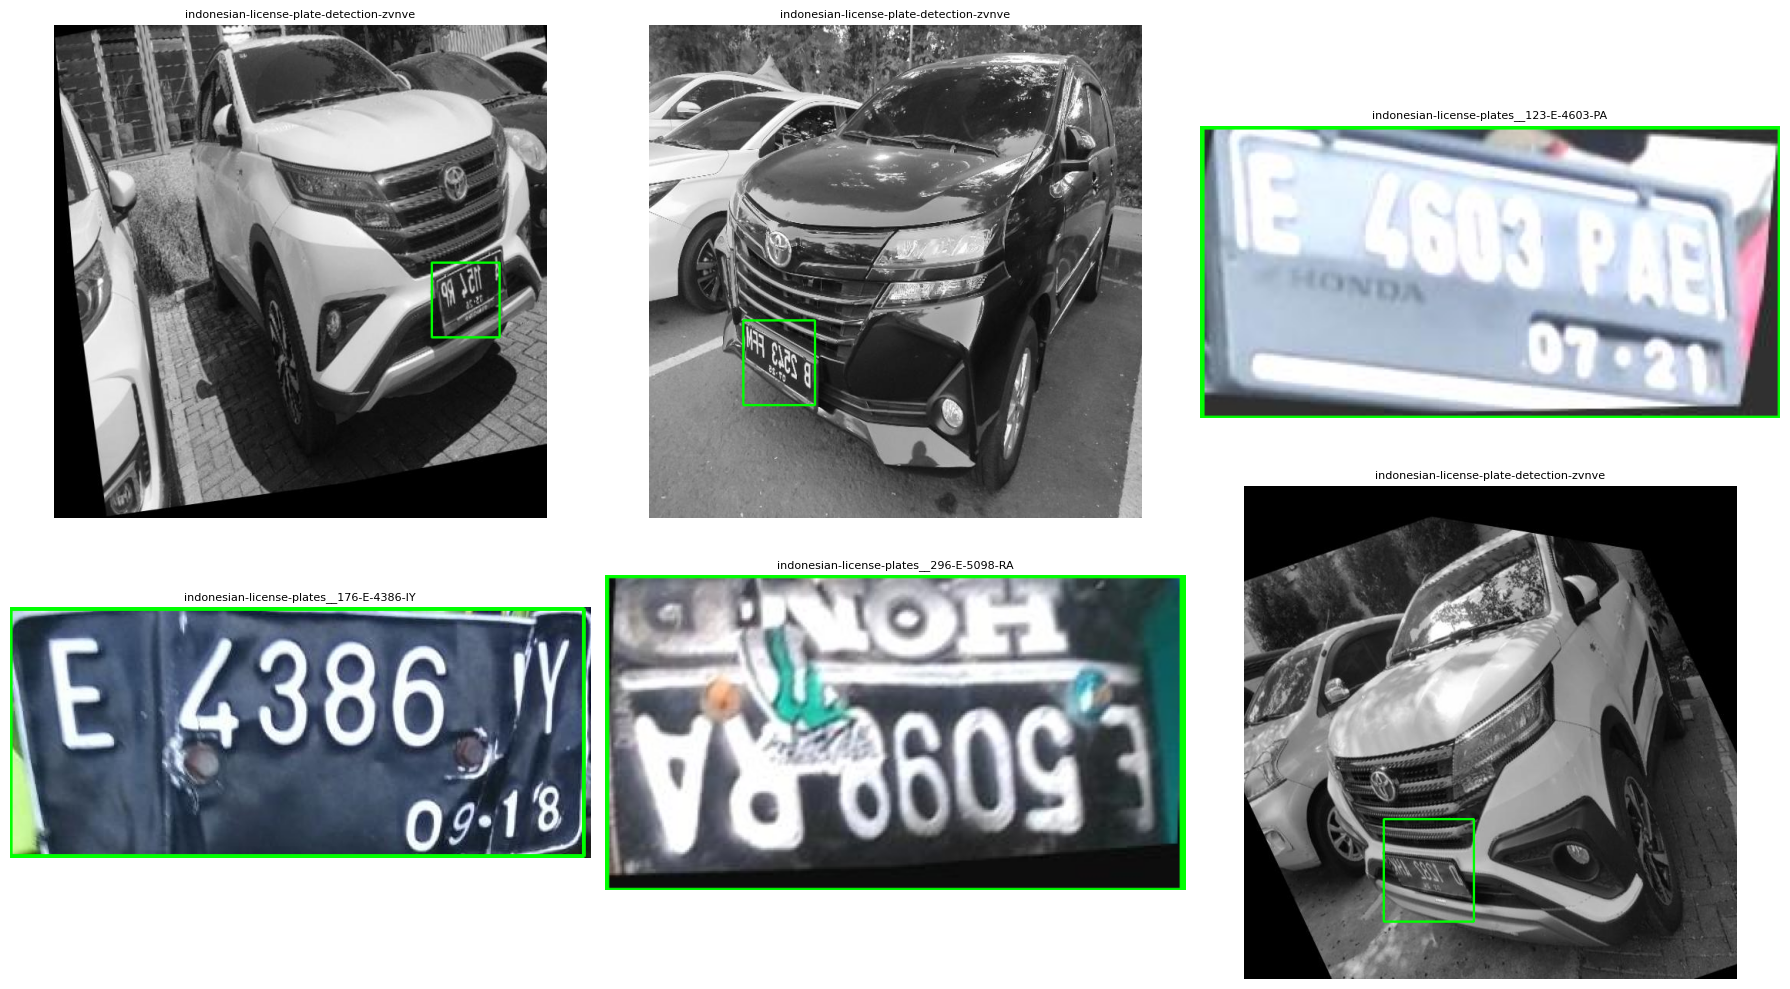

In [21]:
import random, cv2
import matplotlib.pyplot as plt

samples = random.sample(list((DST / 'train' / 'images').glob('*')), 6)
plt.figure(figsize=(18, 10))
for i, img_path in enumerate(samples):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for ln in (DST / 'train' / 'labels' / (img_path.stem + '.txt')).read_text().splitlines():
        _, x, y, bw, bh = map(float, ln.split())
        x1, y1 = int((x - bw/2) * w), int((y - bh/2) * h)
        x2, y2 = int((x + bw/2) * w), int((y + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    plt.subplot(2, 3, i + 1); plt.imshow(img); plt.axis('off'); plt.title(img_path.name[:40], fontsize=8)
plt.tight_layout(); plt.show()

## 8. Buat file konfigurasi `plate.yaml`
File ini dipakai YOLOv8 saat training di langkah 2.

In [22]:
yaml_text = f'''path: {DST}
train: train/images
val: valid/images
test: test/images

names:
  0: plate
'''
(Path(ROOT) / 'plate.yaml').write_text(yaml_text)
print(yaml_text)

path: /content/drive/MyDrive/0-KEPSTON/model_alpr/data/detect
train: train/images
val: valid/images
test: test/images

names:
  0: plate



## 9. (Opsional) Tambahkan foto sendiri dari gerbang
1. Simpan foto dari webcam gerbang (1280×720) ke `MyDrive/alpr/data/raw/lokal/`.
2. Unggah ke project Roboflow milik sendiri, anotasi satu kelas `plate`, ekspor format **YOLOv8**.
3. Unduh dengan sel nomor 5 (ganti WORKSPACE/PROJECT/VERSION), lalu jalankan ulang sel 6–8.

**Simpan sebagian foto lokal khusus untuk `test`** (jangan dipakai training). Data ini dipakai untuk uji 30 sampel plat di rencana pengujian CPE103.

---
### Checklist selesai Langkah 1
- [ ] GPU terdeteksi dan `ultralytics.checks()` berhasil
- [ ] YOLOv8n berhasil mendeteksi gambar contoh
- [ ] `data/detect/{train,valid,test}` terisi, tanpa label kosong/rusak
- [ ] `plate.yaml` tersimpan di `MyDrive/alpr/`

**Langkah berikutnya (2):** training YOLOv8n dengan `plate.yaml`.

CHECK DATASET

In [13]:
from pathlib import Path
src = Path(f'{ROOT}/data/raw/publik')
for d in sorted(p for p in src.iterdir() if p.is_dir()):
    for split in ['train', 'valid', 'test']:
        n = len(list((d / split / 'images').glob('*'))) if (d / split / 'images').exists() else 0
        print(f'{d.name:40s} {split:5s} {n:5d} gambar')
!cat {ROOT}/data/raw/publik/*/data.yaml

indonesia-anpr-hruo7                     train   102 gambar
indonesia-anpr-hruo7                     valid    28 gambar
indonesia-anpr-hruo7                     test     18 gambar
indonesian-license-plate-detection-zvnve train   936 gambar
indonesian-license-plate-detection-zvnve valid    89 gambar
indonesian-license-plate-detection-zvnve test     44 gambar
indonesian-license-plates                train  1416 gambar
indonesian-license-plates                valid     0 gambar
indonesian-license-plates                test     30 gambar
indonesian-motorcycle-plate              train   486 gambar
indonesian-motorcycle-plate              valid     0 gambar
indonesian-motorcycle-plate              test      0 gambar
names:
- license-plate
nc: 1
roboflow:
  license: CC BY 4.0
  project: indonesia-anpr-hruo7
  url: https://app.roboflow.com/muhammads-workspace-a5wiz/indonesia-anpr-hruo7/1
  version: 1
  workspace: muhammads-workspace-a5wiz
test: ../test/images
train: ../train/images
val: ../val

In [19]:
def clip_labels(split):
    fixed, dropped = 0, 0
    for lbl in (DST / split / 'labels').glob('*.txt'):
        out = []
        for ln in lbl.read_text().splitlines():
            p = ln.split()
            if len(p) != 5:
                continue
            x, y, w, h = map(float, p[1:])
            # ubah ke x1,y1,x2,y2 lalu potong ke rentang 0–1
            x1, y1 = max(0.0, x - w/2), max(0.0, y - h/2)
            x2, y2 = min(1.0, x + w/2), min(1.0, y + h/2)
            nw, nh = x2 - x1, y2 - y1
            if nw <= 0.002 or nh <= 0.002:          # box terlalu kecil / rusak -> buang
                dropped += 1
                continue
            new = f'0 {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {nw:.6f} {nh:.6f}'
            if new != ' '.join(p):
                fixed += 1
            out.append(new)
        lbl.write_text('\n'.join(out))
    print(f'{split:5s}: {fixed} box dirapikan, {dropped} box dibuang')

for s in ['train', 'valid', 'test']:
    clip_labels(s)

train: 2640 box dirapikan, 2 box dibuang
valid: 757 box dirapikan, 2 box dibuang
test : 344 box dirapikan, 3 box dibuang
